Language: **English (default)** | [Polski](examples.ipynb)

# Lecture 02 -- experiment: the perceptron, MLPs, and activation functions

Companion material to [`lecture.en.md`](lecture.en.md). We show: (1) a single
perceptron fails on XOR, (2) a hand-constructed MLP solves XOR with no
training, (3) activation functions and their derivatives, (4)-(5) a linear
model vs. an MLP on nonlinearly separable data, (6) what happens when we
remove the nonlinearity.

In [1]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

torch.manual_seed(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


## 1. The XOR problem and a single perceptron

Four points, the label is the XOR of the coordinates. We train a single
linear layer (`nn.Linear(2, 1)`) as a classifier -- this is exactly the
perceptron from the *Formal model* section, just trained by gradient
descent instead of Rosenblatt's classical rule (because our layer computes
the loss from a differentiable logit).

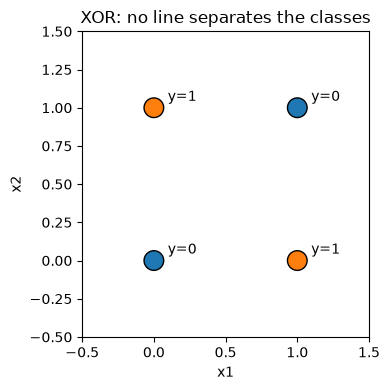

In [2]:
X_xor = torch.tensor([[0., 0.], [1., 0.], [0., 1.], [1., 1.]], device=device)
y_xor = torch.tensor([0., 1., 1., 0.], device=device)

plt.figure(figsize=(4, 4))
colors = ["tab:blue" if label == 0 else "tab:orange" for label in y_xor.cpu()]
plt.scatter(X_xor[:, 0].cpu(), X_xor[:, 1].cpu(), c=colors, s=200, edgecolor="black")
for (x1, x2), label in zip(X_xor.cpu().tolist(), y_xor.cpu().tolist()):
    plt.annotate(f"y={int(label)}", (x1, x2), textcoords="offset points", xytext=(10, 5))
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("XOR: no line separates the classes")
plt.xlim(-0.5, 1.5)
plt.ylim(-0.5, 1.5)
plt.tight_layout()
plt.show()

In [3]:
torch.manual_seed(0)
linear_xor = nn.Linear(2, 1).to(device)
optimizer = torch.optim.Adam(linear_xor.parameters(), lr=0.5)
loss_fn = nn.BCEWithLogitsLoss()

loss_history_xor = []
for epoch in range(500):
    optimizer.zero_grad()
    logits = linear_xor(X_xor).squeeze(-1)
    loss = loss_fn(logits, y_xor)
    loss.backward()
    optimizer.step()
    loss_history_xor.append(loss.item())

with torch.no_grad():
    probs = torch.sigmoid(linear_xor(X_xor).squeeze(-1))
    preds = (probs > 0.5).float()
    accuracy = (preds == y_xor).float().mean().item()
    final_weight = linear_xor.weight.detach().clone()
    final_bias = linear_xor.bias.detach().clone()

ln2 = torch.log(torch.tensor(2.0)).item()
print(f"Final loss: {loss_history_xor[-1]:.4f}  (ln(2) = {ln2:.4f} = random guessing)")
print(f"Probabilities: {[round(p, 3) for p in probs.tolist()]}")
print(f"Weights: {final_weight.tolist()}  bias: {final_bias.tolist()}")
print(f"Accuracy (threshold 0.5): {accuracy:.2f}  (target: {y_xor.tolist()})")

Final loss: 0.6931  (ln(2) = 0.6931 = random guessing)
Probabilities: [0.5, 0.5, 0.5, 0.5]
Weights: [[1.6707917893654667e-07, 6.381922901255166e-08]]  bias: [8.245521598837513e-08]
Accuracy (threshold 0.5): 0.75  (target: [0.0, 1.0, 1.0, 0.0])


The loss gets stuck exactly at $\ln 2 \approx 0.69$ -- the loss of random
guessing with two equally sized classes -- **regardless of the random
seed**. Interestingly, the weights and bias converge toward zero, so the
model predicts a probability $\approx 0.5$ for *every* point: by XOR's
symmetry (improving the prediction for one point worsens it for another by
exactly the same amount), the best the optimizer can do is "give up" and
not favor either class. In this regime, **accuracy computed with a 0.5
threshold is an artifact of numerical noise** around $0.5$ (it changes
between runs with different seeds -- we checked this) -- it is the loss
itself, not accuracy, that is the reliable signal here that the model
learned nothing.

## 2. A hand-constructed MLP solves XOR

The same weights as in the lecture's worked example -- no training.

In [4]:
manual_mlp = nn.Sequential(
    nn.Linear(2, 2),
    nn.ReLU(),
    nn.Linear(2, 1),
).to(device)

with torch.no_grad():
    manual_mlp[0].weight.copy_(torch.tensor([[1., 1.], [1., 1.]]))
    manual_mlp[0].bias.copy_(torch.tensor([0., -1.]))
    manual_mlp[2].weight.copy_(torch.tensor([[1., -2.]]))
    manual_mlp[2].bias.copy_(torch.tensor([0.]))

with torch.no_grad():
    manual_out = manual_mlp(X_xor).squeeze(-1)

print(f"MLP output: {manual_out.tolist()}")
print(f"Target:     {y_xor.tolist()}")
assert torch.allclose(manual_out, y_xor, atol=1e-6)
print("OK: the hand-constructed MLP solves XOR exactly, with no training.")

MLP output: [0.0, 1.0, 1.0, 0.0]
Target:     [0.0, 1.0, 1.0, 0.0]
OK: the hand-constructed MLP solves XOR exactly, with no training.


## 3. Activation functions: plots and derivatives

We compute the derivative two ways -- from the closed-form formula and
through `autograd` -- just as in lecture 1 we verified the MSE gradient.

In [5]:
z = torch.linspace(-5, 5, 200)

def sigmoid(z):
    return 1 / (1 + torch.exp(-z))

def sigmoid_grad_formula(z):
    s = sigmoid(z)
    return s * (1 - s)

def tanh_grad_formula(z):
    return 1 - torch.tanh(z) ** 2

def relu_grad_formula(z):
    return (z > 0).float()

activations = {
    "sigmoid": (sigmoid, sigmoid_grad_formula),
    "tanh": (torch.tanh, tanh_grad_formula),
    "ReLU": (torch.relu, relu_grad_formula),
}

autograd_grads = {}
for name, (fn, _) in activations.items():
    z_ag = z.clone().requires_grad_(True)
    out = fn(z_ag)
    out.sum().backward()
    autograd_grads[name] = z_ag.grad.clone()

for name, (fn, grad_formula) in activations.items():
    formula_grad = grad_formula(z)
    max_diff = (formula_grad - autograd_grads[name]).abs().max().item()
    print(f"{name:8s} max|formula - autograd| = {max_diff:.2e}")
    assert torch.allclose(formula_grad, autograd_grads[name], atol=1e-5)
print("OK: the formula and autograd derivatives agree.")

sigmoid  max|formula - autograd| = 7.82e-08
tanh     max|formula - autograd| = 0.00e+00
ReLU     max|formula - autograd| = 0.00e+00
OK: the formula and autograd derivatives agree.


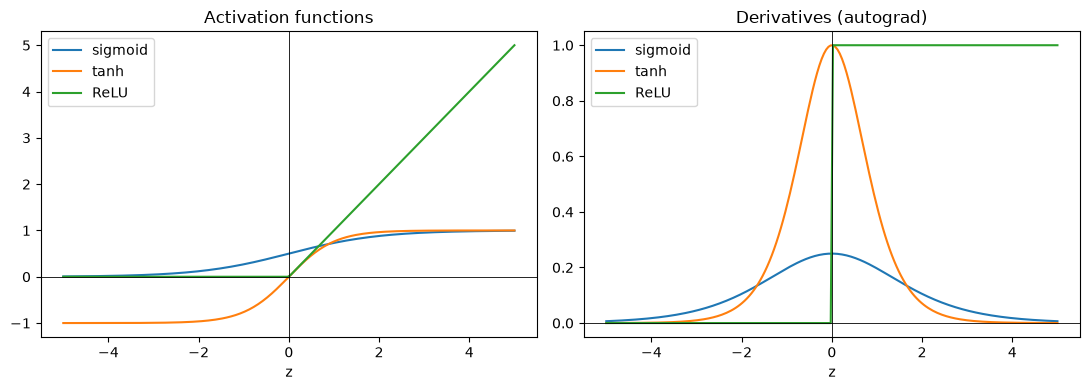

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for name, (fn, _) in activations.items():
    axes[0].plot(z, fn(z), label=name)
axes[0].axhline(0, color="black", linewidth=0.6)
axes[0].axvline(0, color="black", linewidth=0.6)
axes[0].set_title("Activation functions")
axes[0].set_xlabel("z")
axes[0].legend()

for name in activations:
    axes[1].plot(z, autograd_grads[name], label=name)
axes[1].axhline(0, color="black", linewidth=0.6)
axes[1].axvline(0, color="black", linewidth=0.6)
axes[1].set_title("Derivatives (autograd)")
axes[1].set_xlabel("z")
axes[1].legend()

plt.tight_layout()
plt.show()

## 4. Data: two interleaving half-moons

We generate them parametrically (no downloads, no new dependencies) and
split into a training/test set.

N_train=240, N_test=60


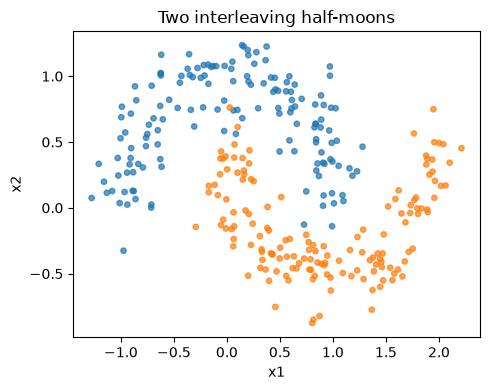

In [7]:
def make_moons(n_samples, noise, seed):
    g = torch.Generator().manual_seed(seed)
    n0 = n_samples // 2
    n1 = n_samples - n0

    theta0 = torch.pi * torch.rand(n0, generator=g)
    moon0 = torch.stack([torch.cos(theta0), torch.sin(theta0)], dim=1)

    theta1 = torch.pi * torch.rand(n1, generator=g)
    moon1 = torch.stack([1 - torch.cos(theta1), 1 - torch.sin(theta1) - 0.5], dim=1)

    X = torch.cat([moon0, moon1], dim=0)
    y = torch.cat([torch.zeros(n0), torch.ones(n1)])
    X = X + noise * torch.randn(X.shape[0], 2, generator=g)

    perm = torch.randperm(X.shape[0], generator=g)
    return X[perm], y[perm]


X, y = make_moons(n_samples=300, noise=0.15, seed=0)

n = X.shape[0]
perm = torch.randperm(n)
n_test = int(0.2 * n)
test_idx, train_idx = perm[:n_test], perm[n_test:]

X_train, y_train = X[train_idx].to(device), y[train_idx].to(device)
X_test, y_test = X[test_idx].to(device), y[test_idx].to(device)

print(f"N_train={len(train_idx)}, N_test={len(test_idx)}")

colors_moons = ["tab:blue" if v == 0 else "tab:orange" for v in y]
plt.figure(figsize=(5, 4))
plt.scatter(X[:, 0], X[:, 1], c=colors_moons, s=15, alpha=0.7)
plt.title("Two interleaving half-moons")
plt.xlabel("x1")
plt.ylabel("x2")
plt.tight_layout()
plt.show()

## 5. Linear model vs. MLP: training and decision boundaries

`nn.Linear(2, 1)` is exactly $z = Wx+b$. For the MLP we insert `nn.ReLU()`
between two such layers. `optimizer.step()` performs the same parameter
update we wrote by hand in lecture 1 as `w -= lr * w.grad` -- here it is
delegated to `torch.optim.Adam` as a tool (the mechanics of optimizers is
lecture 4).

In [8]:
def build_model(hidden=None, activation="relu"):
    if hidden is None:
        return nn.Linear(2, 1)
    act_layer = {"relu": nn.ReLU, "identity": nn.Identity}[activation]
    return nn.Sequential(
        nn.Linear(2, hidden),
        act_layer(),
        nn.Linear(hidden, 1),
    )


def train_classifier(model, X_train, y_train, epochs=500, lr=0.1, seed=0):
    torch.manual_seed(seed)
    model = model.to(X_train.device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()
    loss_history = []
    for epoch in range(epochs):
        optimizer.zero_grad()
        logits = model(X_train).squeeze(-1)
        loss = loss_fn(logits, y_train)
        loss.backward()
        optimizer.step()
        loss_history.append(loss.item())
    return model, loss_history


def accuracy(model, X, y):
    with torch.no_grad():
        preds = (torch.sigmoid(model(X).squeeze(-1)) > 0.5).float()
        return (preds == y).float().mean().item()


def report(name, model, loss):
    train_acc = accuracy(model, X_train, y_train)
    test_acc = accuracy(model, X_test, y_test)
    print(f"{name:14s} loss={loss:.4f}  train_acc={train_acc:.3f}  test_acc={test_acc:.3f}")


linear_model, linear_loss_hist = train_classifier(build_model(), X_train, y_train)
mlp_model, mlp_loss_hist = train_classifier(
    build_model(hidden=16, activation="relu"), X_train, y_train
)

report("Linear", linear_model, linear_loss_hist[-1])
report("MLP (ReLU)", mlp_model, mlp_loss_hist[-1])

Linear         loss=0.2817  train_acc=0.863  test_acc=0.883
MLP (ReLU)     loss=0.0125  train_acc=0.996  test_acc=0.967


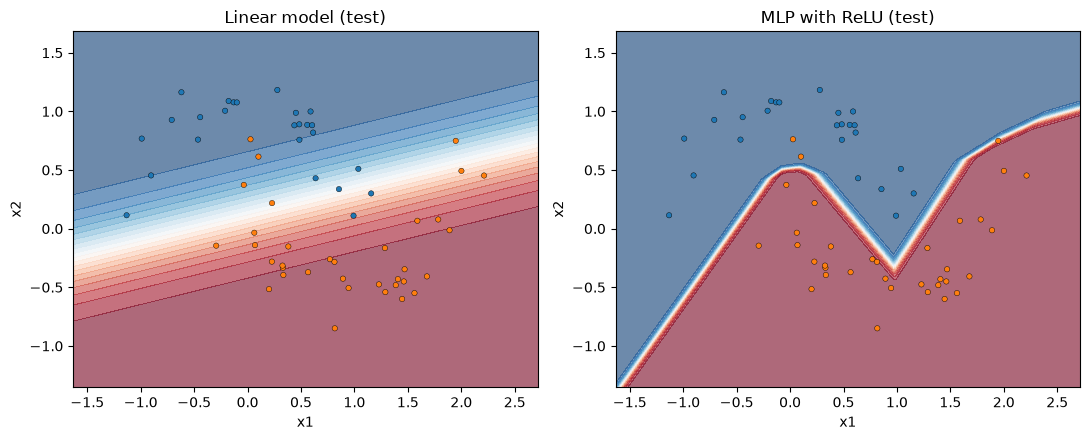

In [9]:
def plot_decision_boundary(ax, model, X, y, title):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = torch.meshgrid(
        torch.linspace(x_min, x_max, 200),
        torch.linspace(y_min, y_max, 200),
        indexing="xy",
    )
    grid = torch.stack([xx.reshape(-1), yy.reshape(-1)], dim=1).to(X.device)
    with torch.no_grad():
        probs = torch.sigmoid(model(grid).squeeze(-1)).cpu().reshape(xx.shape)

    ax.contourf(xx.cpu(), yy.cpu(), probs, levels=20, cmap="RdBu_r", alpha=0.6, vmin=0, vmax=1)
    ax.scatter(
        X[:, 0].cpu(), X[:, 1].cpu(),
        c=["tab:blue" if v == 0 else "tab:orange" for v in y.cpu()],
        s=15, edgecolor="black", linewidth=0.3,
    )
    ax.set_title(title)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")


fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
plot_decision_boundary(axes[0], linear_model, X_test, y_test, "Linear model (test)")
plot_decision_boundary(axes[1], mlp_model, X_test, y_test, "MLP with ReLU (test)")
plt.tight_layout()
plt.show()

## 6. Ablation: what happens without the nonlinearity?

The exact same architecture as the MLP above (two `nn.Linear` layers), but
with `nn.Identity()` instead of `nn.ReLU()` between them.

Linear         loss=0.2817  train_acc=0.863  test_acc=0.883
MLP no act.    loss=0.2817  train_acc=0.863  test_acc=0.883
MLP (ReLU)     loss=0.0125  train_acc=0.996  test_acc=0.967


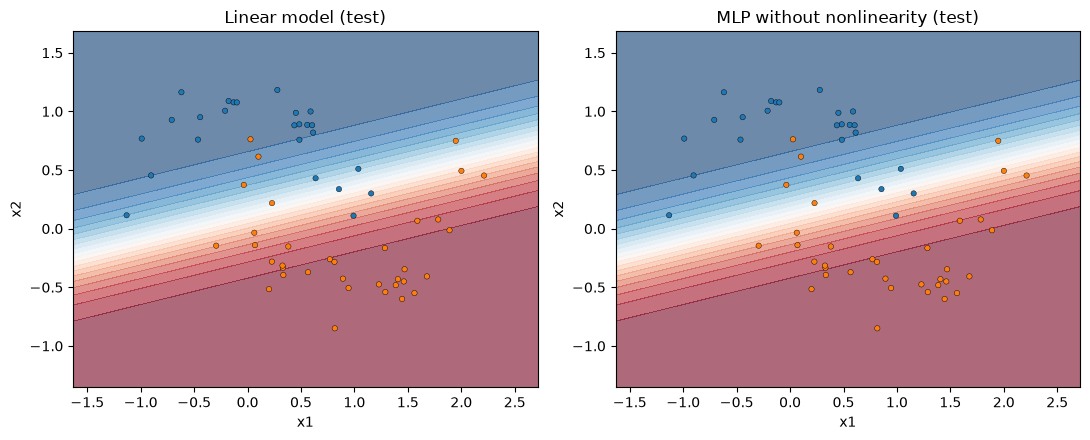

In [10]:
noact_model, noact_loss_hist = train_classifier(
    build_model(hidden=16, activation="identity"), X_train, y_train
)

report("Linear", linear_model, linear_loss_hist[-1])
report("MLP no act.", noact_model, noact_loss_hist[-1])
report("MLP (ReLU)", mlp_model, mlp_loss_hist[-1])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
plot_decision_boundary(axes[0], linear_model, X_test, y_test, "Linear model (test)")
plot_decision_boundary(axes[1], noact_model, X_test, y_test, "MLP without nonlinearity (test)")
plt.tight_layout()
plt.show()

## Summary

- A single perceptron gets stuck on XOR at the level of random guessing;
  a hand-constructed MLP with ReLU solves it perfectly, with no training.
- The sigmoid/tanh/ReLU derivatives from `autograd` agree with the
  closed-form formulas.
- On the half-moons, the MLP with ReLU clearly beats the linear model on
  the test set; the MLP **without** nonlinearity achieves (within the
  randomness of optimization) the same loss and accuracy as the purely
  linear model -- empirical confirmation of the proof about composing
  affine transformations.

Discussion questions and bibliography: see [`lecture.en.md`](lecture.en.md).